# 01 · Finite volumes in 1D: conservation laws, fluxes and a first gradient

This is the first of six notebooks that go from a "simple" 20-line finite-volume solver to using
**diffhydro** to inverse-solve the initial conditions of a turbulent flow so that it writes your favorite logo! Exciting!

| # | notebook | CFD | autodiff |
|---|---|---|---|
| **01** | **finite volumes in 1D** | advection, Burgers, CFL, shocks | first `jax.jit` / `jax.grad` |
| 02 | autodiff through time | — | forward vs reverse mode, memory, first inverse problems |
| 03 | Euler equations in 1D | Riemann problems, HLL/HLLC, MUSCL | inferring a shock tube's initial state |
| 04 | diffhydro | same physics, production solver, 2D | gradients through `diffhydro` |
| 05 | decaying turbulence | random fields, spectra, 2D turbulence | sensitivity maps, chaos |
| 06 | the letter | — | full inverse problem: ICs → image |

**In this notebook you will:**
- derive the finite-volume update and see why it conserves mass to machine precision,
- solve linear advection with three different numerical fluxes (one of them explodes),
- meet the CFL condition and numerical diffusion,
- watch Burgers' equation form a shock, and see why the *conservative* form matters,
- port the solver to JAX and take your first derivative *of a whole simulation*.

Only `numpy`, `jax` and `matplotlib` are used.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Conservation laws and the finite-volume update

Many equations in fluid dynamics are **conservation laws**,

$$\partial_t u + \partial_x f(u) = 0,$$

where $u$ is a conserved density (mass, momentum, energy …) and $f(u)$ its **flux**.
Integrate over a cell $[x_{i-1/2}, x_{i+1/2}]$ and a time step $[t^n, t^{n+1}]$. Writing
$\bar u_i^n$ for the cell average and $F_{i+1/2}$ for the time-averaged flux through the right face gives the *exact* statement

$$\bar u_i^{n+1} = \bar u_i^n - \frac{\Delta t}{\Delta x}\left(F_{i+1/2} - F_{i-1/2}\right).$$

Nothing has been approximated yet: the only approximation in a finite-volume (FV) method is **how we estimate the
face flux** $F_{i+1/2} \approx \mathcal{F}(\bar u_i, \bar u_{i+1})$ from the neighbouring cell averages.
Every face flux leaves one cell and enters its neighbour, so the sum $\sum_i \bar u_i$ telescopes: on a periodic
grid the total is conserved **exactly**, whatever flux function we pick.

In code the update is two lines. With `np.roll(u, -1)` giving the right neighbour $u_{i+1}$:

In [2]:
def fv_step(u, dt, dx, numerical_flux):
    # F[i] is the flux through the RIGHT face of cell i (i + 1/2); periodic boundaries via roll
    F = numerical_flux(u, np.roll(u, -1), dt, dx)
    return u - dt / dx * (F - np.roll(F, 1))

N, L = 200, 1.0
dx = L / N
x = (np.arange(N) + 0.5) * dx          # cell centres

def initial_profile(x):
    # a square wave (discontinuous) next to a Gaussian (smooth)
    return np.where(np.abs(x - 0.3) < 0.1, 1.0, 0.0) + np.exp(-((x - 0.7) / 0.05) ** 2)

u0 = initial_profile(x)

## 2. Linear advection: three fluxes

For $f(u) = a u$ with constant speed $a > 0$ the exact solution just translates: $u(x, t) = u_0(x - a t)$.
Three natural guesses for the face flux:

| flux | $\mathcal F(u_L, u_R)$ | idea |
|---|---|---|
| centred | $\tfrac12 a (u_L + u_R)$ | average the two sides |
| upwind | $a\,u_L$ (for $a>0$) | information comes from the left |
| Lax–Friedrichs | $\tfrac12 a (u_L + u_R) - \tfrac12 \tfrac{\Delta x}{\Delta t}(u_R - u_L)$ | centred + explicit diffusion |

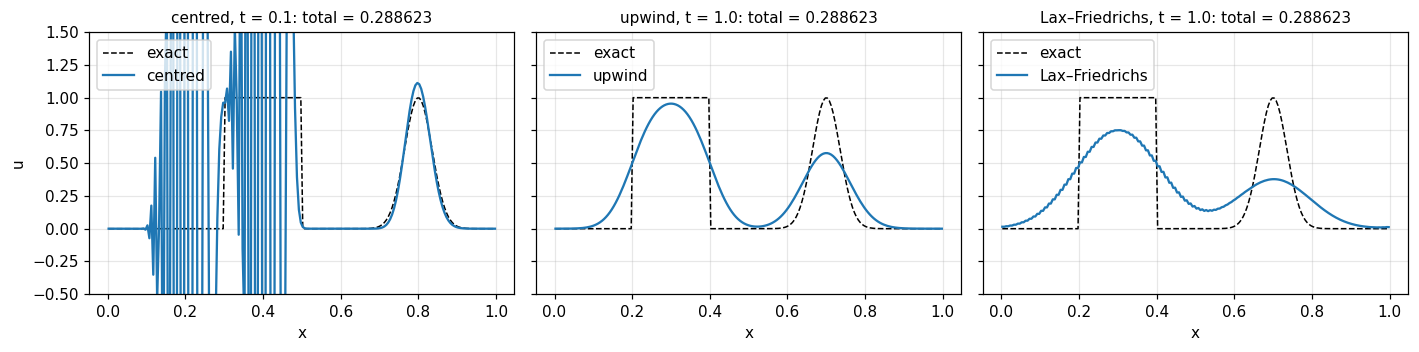

In [3]:
a = 1.0

def flux_centred(uL, uR, dt, dx):
    return 0.5 * a * (uL + uR)

def flux_upwind(uL, uR, dt, dx):
    return a * uL

def flux_lax_friedrichs(uL, uR, dt, dx):
    return 0.5 * a * (uL + uR) - 0.5 * dx / dt * (uR - uL)

def run_advection(u0, flux, dx, cfl=0.5, t_end=1.0):
    dt = cfl * dx / abs(a)
    nsteps = int(round(t_end / dt))
    u = u0.copy()
    for _ in range(nsteps):
        u = fv_step(u, dt, dx, flux)
    return u

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (name, flux) in zip(axes, [("centred", flux_centred), ("upwind", flux_upwind),
                                    ("Lax–Friedrichs", flux_lax_friedrichs)]):
    t_end = 0.1 if name == "centred" else 1.0   # the centred run overflows long before t = 1
    u = run_advection(u0, flux, dx, t_end=t_end)
    ax.plot(x, initial_profile((x - a * t_end) % L), "k--", lw=1, label="exact")
    ax.plot(x, u, lw=1.5, label=name)
    ax.set_title(f"{name}, t = {t_end}: total = {u.sum() * dx:.6f}", fontsize=10)
    ax.set_ylim(-0.5, 1.5); ax.set_xlabel("x"); ax.legend(loc="upper left")
axes[0].set_ylabel("u")
plt.tight_layout()

Three lessons in this one figure:

* **The centred flux is unconditionally unstable** with forward-Euler time stepping (common knowledge in CFD). Grid-scale wiggles grow
  exponentially (a classic CFD von Neumann analysis gives an amplification factor $|1 - i C \sin k\Delta x| > 1$ for every mode);
  after a tenth of a period they already dominate, and by $t=1$ they overflow. Yet the total is still conserved exactly:
  **conservation is not stability**.
* **Upwind is stable but smears** the profile: the scheme adds *numerical diffusion* (like all finite volume methods to different extents).
* **Lax–Friedrichs is even more diffusive**, with coefficient $\Delta x^2/2\Delta t$. It also shows a faint odd–even
  zig-zag since eighbouring cells are only coupled through their *other* neighbours.

### The CFL condition

The upwind update only uses information from cell $i-1$. During one step the true solution moves $a\Delta t$, so if
$a\Delta t > \Delta x$ the information needed lies *outside* the stencil. The Courant number
$C = a\,\Delta t / \Delta x$ must satisfy $C \le 1$, the **Courant–Friedrichs–Lewy** condition.

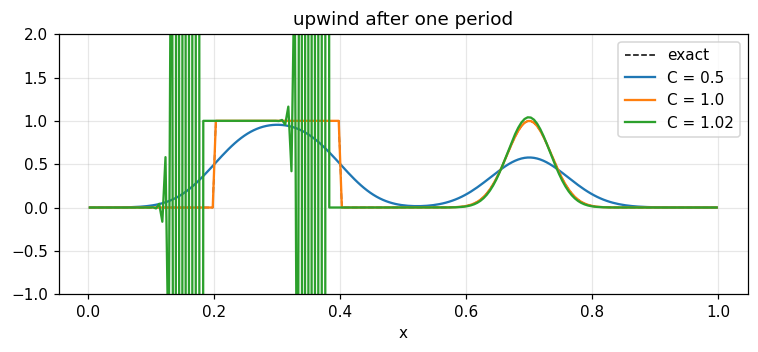

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(x, u0, "k--", lw=1, label="exact")
for cfl in (0.5, 1.0, 1.02):
    u = run_advection(u0, flux_upwind, dx, cfl=cfl)
    ax.plot(x, u, label=f"C = {cfl}")
ax.set_ylim(-1, 2); ax.legend(); ax.set_xlabel("x"); ax.set_title("upwind after one period")
plt.tight_layout()

At exactly $C = 1$ upwind shifts the profile by one cell per step, which is the exact answer. A Courant number just 2% over the limit blows up.
Real solvers compute $\Delta t$ every step from the fastest signal speed on the grid, as we will for Burgers.

### Numerical diffusion and order of accuracy

A Taylor expansion of the upwind scheme gives its *modified equation*. What the scheme actually solves is

$$\partial_t u + a\,\partial_x u = \underbrace{\tfrac{a\Delta x}{2}(1 - C)}_{\nu_\text{num}}\,\partial_x^2 u + \mathcal O(\Delta x^2).$$

The numerical viscosity $\nu_\text{num} \propto \Delta x$ makes the scheme **first-order accurate**. Halving $\Delta x$
halves the error on a smooth profile... Let's measure it on the Gaussian alone! 

measured order: 0.9


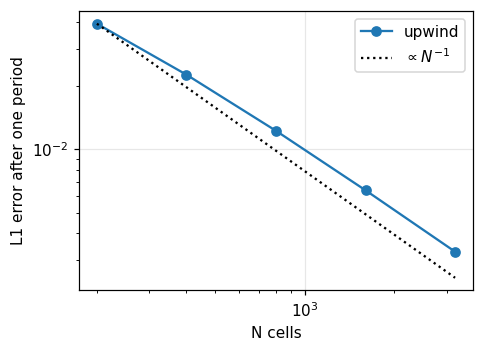

In [5]:
def l1_error(Nc, flux=flux_upwind):
    dxc = L / Nc
    xc = (np.arange(Nc) + 0.5) * dxc
    ug = np.exp(-((xc - 0.5) / 0.08) ** 2)
    return np.mean(np.abs(run_advection(ug, flux, dxc) - ug))

Ns = np.array([200, 400, 800, 1600, 3200])
errs = np.array([l1_error(n) for n in Ns])
fig, ax = plt.subplots(figsize=(4.5, 3.3))
ax.loglog(Ns, errs, "o-", label="upwind")
ax.loglog(Ns, errs[0] * (Ns / Ns[0]) ** -1.0, "k:", label=r"$\propto N^{-1}$")
ax.set_xlabel("N cells"); ax.set_ylabel("L1 error after one period"); ax.legend()
plt.tight_layout()
print("measured order:", -np.polyfit(np.log(Ns), np.log(errs), 1)[0].round(2))

In notebook 03 we will get second-order accuracy by *reconstructing* sloped profiles inside each cell (with the popular 
MUSCL),
and we will see why the slopes must be *limited* near discontinuities.

## 3. Burgers' equation: nonlinearity makes shocks

The inviscid Burgers equation $\partial_t u + \partial_x (u^2/2) = 0$ is the simplest nonlinear conservation law.
Written as $\partial_t u + u\,\partial_x u = 0$, it says each value of $u$ travels at speed $u$.
Fast parts overtake slow parts, the **characteristics** $x = x_0 + u_0(x_0)\,t$ cross, and a **shock** forms.
For $u_0 = \tfrac12 + \tfrac12\sin 2\pi x$ the first crossing happens at $t_b = 1/\max(-u_0') = 1/\pi \approx 0.32$.

For a nonlinear flux we need a *wave speed* to upwind with. The **Rusanov** (local Lax–Friedrichs) flux uses the
largest local speed $s = \max(|u_L|, |u_R|)$:

$$\mathcal F(u_L,u_R) = \tfrac12\big(f(u_L) + f(u_R)\big) - \tfrac12\, s\,(u_R - u_L).$$

This "average of physical fluxes plus wave-speed-weighted jump" is the template for every Riemann solver we will meet, including HLL and HLLC in notebook 03.

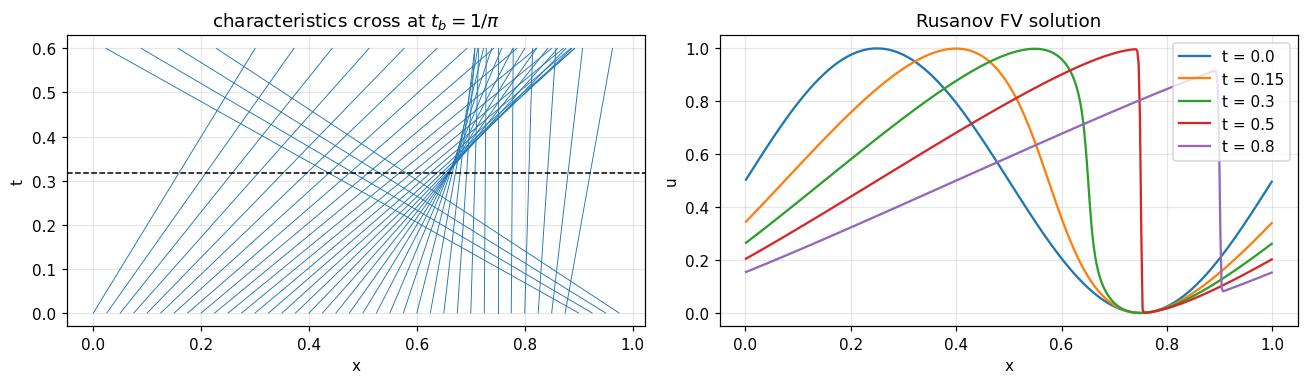

In [6]:
def burgers_flux(u):
    return 0.5 * u ** 2

def flux_rusanov_burgers(uL, uR, dt=None, dx=None):
    s = np.maximum(np.abs(uL), np.abs(uR))
    return 0.5 * (burgers_flux(uL) + burgers_flux(uR)) - 0.5 * s * (uR - uL)

def run_burgers(u0, t_end, dx, cfl=0.8, flux=flux_rusanov_burgers):
    u, t = u0.copy(), 0.0
    while t < t_end - 1e-12:
        dt = min(cfl * dx / np.max(np.abs(u)), t_end - t)    # adaptive CFL time step
        u = fv_step(u, dt, dx, flux)
        t += dt
    return u

N = 400; dx = 1.0 / N; x = (np.arange(N) + 0.5) * dx
u0_b = 0.5 + 0.5 * np.sin(2 * np.pi * x)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.6))
x0 = np.linspace(0, 1, 40, endpoint=False)
for xi in x0:  # characteristics
    tt = np.linspace(0, 0.6, 2)
    ax0.plot((xi + (0.5 + 0.5 * np.sin(2 * np.pi * xi)) * tt) % 1.0, tt, "C0", lw=0.6)
ax0.axhline(1 / np.pi, color="k", ls="--", lw=1)
ax0.set_xlabel("x"); ax0.set_ylabel("t"); ax0.set_title(r"characteristics cross at $t_b = 1/\pi$")
for t_end in (0.0, 0.15, 0.3, 0.5, 0.8):
    ax1.plot(x, run_burgers(u0_b, t_end, dx), label=f"t = {t_end}")
ax1.set_xlabel("x"); ax1.set_ylabel("u"); ax1.legend(); ax1.set_title("Rusanov FV solution")
plt.tight_layout()

After $t_b$ the exact solution is no longer smooth. It has a jump that moves at
$s = [f]/[u] = \tfrac12(u_L + u_R)$ (**Rankine–Hugoniot** speed). The finite-volume solution captures it automatically,
over a couple of cells, because a conservative scheme has to get the jump conditions right.

### Why "conservative form" is not a detail

Discretise the *equivalent-looking* non-conservative form $u_t + u\,u_x = 0$ with upwinding,
$u_i^{n+1} = u_i^n - \tfrac{\Delta t}{\Delta x} u_i (u_i - u_{i-1})$, and apply it to a step $u = 1 \to 0$.
The exact shock moves at speed $\tfrac12(1+0) = \tfrac12$.

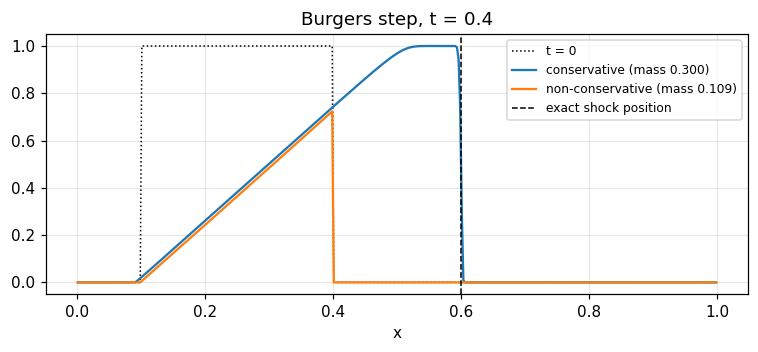

In [7]:
u_step = np.where((x > 0.1) & (x < 0.4), 1.0, 0.0)

def nonconservative_step(u, dt, dx):
    return u - dt / dx * u * (u - np.roll(u, 1))

def run_nonconservative(u0, t_end, dx, cfl=0.8):
    u, t = u0.copy(), 0.0
    while t < t_end - 1e-12:
        dt = min(cfl * dx / np.max(np.abs(u)), t_end - t)
        u = nonconservative_step(u, dt, dx)
        t += dt
    return u

t_end = 0.4
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(x, u_step, "k:", lw=1, label="t = 0")
u_c = run_burgers(u_step, t_end, dx)
u_nc = run_nonconservative(u_step, t_end, dx)
ax.plot(x, u_c, label=f"conservative (mass {u_c.sum() * dx:.3f})")
ax.plot(x, u_nc, label=f"non-conservative (mass {u_nc.sum() * dx:.3f})")
ax.axvline(0.4 + 0.5 * t_end, color="k", ls="--", lw=1, label="exact shock position")
ax.set_xlabel("x"); ax.legend(fontsize=8); ax.set_title(f"Burgers step, t = {t_end}")
plt.tight_layout()

The non-conservative scheme **never moves the shock** ahead of it $u_i = 0$, so the update is zero. (It also loses mass) The rarefaction on the left is fine in both. This is the Lax–Wendroff theorem in action:
if a conservative scheme converges, it converges to a weak solution with the right shock speeds.
Production codes, diffhydro included, therefore evolve the conserved variables $(\rho, \rho\mathbf v, E)$.

## 4. Enter JAX: the same solver, compiled and differentiable (with GPU if you have it)

[JAX](https://jax.readthedocs.io) gives us four things on top of a numpy-like API (`jax.numpy`):

1. **`jax.jit`** traces a Python function once and compiles it with XLA (CPU or GPU),
2. **`jax.grad`, `jax.jacfwd`, …** compute exact derivatives of any composition of `jnp` operations,
3. **`jax.vmap`** vectorises a function over a batch dimension.
4. GPU acceleration (if you have it). If you are on a mac you can look into [mac Metal plugin](https://developer.apple.com/metal/jax/) for jax. Derivative in particular are quite slow on CPU.


Two rules to remember: arrays are **immutable** (no `u[i] = …`; use `u.at[i].set(…)`), and Python control flow
inside jitted functions must not depend on traced values, so loops become `jax.lax.fori_loop` / `jax.lax.scan`.
We turn on 64-bit floats so we can compare against finite differences cleanly.

(Small technical note: One can technically use `jax.lax.while_loop` inside a jitted function, but it will break reverse mode autodiff which we will cover in the next notebook.)

In [ ]:
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

def flux_advection(uL, uR, a):
    # Rusanov flux for f = a u: upwind for either sign of a
    return 0.5 * a * (uL + uR) - 0.5 * jnp.abs(a) * (uR - uL)

def advect_jax(u0, a, dt, dx, nsteps):
    def step(i, u):
        F = flux_advection(u, jnp.roll(u, -1), a)
        return u - dt / dx * (F - jnp.roll(F, 1))
    return jax.lax.fori_loop(0, nsteps, step, u0)

advect_jit = jax.jit(advect_jax, static_argnums=4)   # nsteps sets the loop length: static

N = 2000; dx = 1.0 / N
x = (np.arange(N) + 0.5) * dx
u0 = initial_profile(x)
dt = 0.5 * dx; nsteps = 2000

t0 = time.perf_counter()
u_np = u0.copy()
for _ in range(nsteps):
    u_np = fv_step(u_np, dt, dx, flux_upwind)
t_np = time.perf_counter() - t0

advect_jit(u0, 1.0, dt, dx, nsteps).block_until_ready()        # first call compiles
t0 = time.perf_counter()
u_jx = advect_jit(u0, 1.0, dt, dx, nsteps).block_until_ready()
t_jx = time.perf_counter() - t0
print(f"numpy loop: {t_np * 1e3:.1f} ms   jitted JAX: {t_jx * 1e3:.1f} ms   "
      f"max |diff| = {np.abs(u_np - np.asarray(u_jx)).max():.1e}")

numpy loop: 54.4 ms   jitted JAX: 8.6 ms   max |diff| = 1.0e-15


(For $a > 0$ the Rusanov flux *is* the upwind flux, hence the identical answers.)

Note how similar the syntax looks to standard numpy! How easy :D 

### Your first derivative of a simulation

Lets now ask question about the *whole simulation*... **how does the value of $u$ at $x_\star = 0.75$ after time $T$ change
if we change the advection speed $a$?** For a smooth profile the exact answer is
$\partial_a u_0(x - aT) = -T\,u_0'(x - aT)$. We can get the numerical answer with `jax.grad` and check it against central
finite differences. We will keep $\Delta t$ and the number of steps fixed, so $T$ does not depend on $a$.

In [9]:
N = 400; dx = 1.0 / N; x = (np.arange(N) + 0.5) * dx
u_smooth = jnp.exp(-((x - 0.5) / 0.08) ** 2)
dt, nsteps = 0.4 * dx, 50                      # T = 0.05
T = dt * nsteps
i_star = int(0.61 / dx)                 # on the flank of the bump, where u0' is large

def observable(a):
    return advect_jax(u_smooth, a, dt, dx, nsteps)[i_star]

g_ad = jax.grad(observable)(1.0)
h = 1e-5
g_fd = (observable(1.0 + h) - observable(1.0 - h)) / (2 * h)
xs = x[i_star] - 1.0 * T
g_exact = -T * (-2 * (xs - 0.5) / 0.08 ** 2) * np.exp(-((xs - 0.5) / 0.08) ** 2)
print(f"autodiff      d u(x*) / da = {g_ad:.8f}")
print(f"finite diff                = {g_fd:.8f}")
print(f"continuum (no num. diff.)  = {g_exact:.8f}")

autodiff      d u(x*) / da = 0.52170433
finite diff                = 0.52170433
continuum (no num. diff.)  = 0.53253808


Autodiff and finite differences agree to many digits. Both differentiate *the discrete scheme*, numerical diffusion
included, which is why they differ by a few per cent from the continuum answer. This is an important distinction to keep in mind. **autodiff gives the
exact gradient of the code you wrote**, not of the PDE you had in mind.

Because the solver is now a differentiable function of its inputs, we can also get the derivative of **every** output
cell at once. With one input and many outputs, *forward mode* (`jax.jacfwd`) is the natural tool, although less relevant for high dimensional optimization tasks.

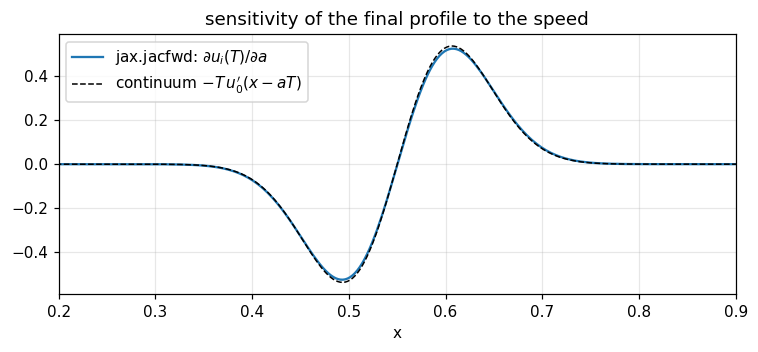

In [10]:
du_da = jax.jacfwd(lambda a: advect_jax(u_smooth, a, dt, dx, nsteps))(1.0)
xs = x - 1.0 * T
exact = -T * (-2 * (xs - 0.5) / 0.08 ** 2) * np.exp(-((xs - 0.5) / 0.08) ** 2)
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(x, du_da, label=r"jax.jacfwd: $\partial u_i(T)/\partial a$")
ax.plot(x, exact, "k--", lw=1, label=r"continuum $-T\,u_0'(x - aT)$")
ax.set_xlim(0.2, 0.9); ax.set_xlabel("x"); ax.legend(); ax.set_title("sensitivity of the final profile to the speed")
plt.tight_layout()

## Summary and what's next

* Finite-volume methods update cell averages with **face fluxes**. Conservation is built in; stability and accuracy come from the flux.
* Explicit schemes need **CFL** $\le 1$. First-order upwinding adds numerical diffusion $\propto \Delta x$.
* Nonlinear conservation laws form **shocks**. Only the conservative form gets their speed right.
* In JAX, a simulation is just a function, so we can `jit` it and differentiate it.

In **notebook 02** we look under the hood of `jax.grad` for time-stepping codes, i.e. forward versus reverse mode, why reverse mode
needs memory proportional to the number of time steps (and how checkpointing fixes it), where gradients go wrong, and
our first **inverse problems** (hurray!), recovering a parameter and then an entire initial condition from the final state.